In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print('Libraries loaded')

Libraries loaded


### Join the supervised stressed_state label onto the unsupervised archetype panel

This notebook continues the archetype series (after `03_balanced_clustering.ipynb`) by joining the supervised `stressed_state` label onto the labelled panel. Each active looping day gets its archetype (RQ1/RQ2) and whether it was a stressed day (from the supervised pipeline in `../whale-risk-supervised/`, RQ3). The archetypes were built without ever seeing the stress label, so the overlap is an independent cross-check of the two methods as well as a way to risk-grade the archetypes.

In [2]:
arch = pd.read_csv("panel_archetypes.csv", parse_dates=["date"])
lab = pd.read_csv("../whale-risk-supervised/whale_features_labeled.csv", parse_dates=["date"])

panel = arch.merge(
    lab[["whale_id", "date", "stressed_state"]],
    on=["whale_id", "date"],
    how="left",
)

matched = panel["stressed_state"].notna().sum()
print(f"{matched} of {len(panel)} archetype days matched a stressed_state label")
assert matched == len(panel), "some archetype days did not match a stressed_state label"
print(f"overall stressed share on active looping days: {panel['stressed_state'].mean() * 100:.1f}%")

457 of 457 archetype days matched a stressed_state label
overall stressed share on active looping days: 27.6%


Joined on `whale_id` and `date`, both shared across the two pipelines. All 457 active looping days find a label, so nothing is dropped. About 28% of those days are flagged stressed, which is the baseline the per-archetype rates are compared against.

### Stressed share by archetype

In [3]:
ARCH_ORDER = ["moderate leverage", "high-LTV hold", "extreme leverage", "idle / outlier"]

by_arch = (
    panel.groupby("cluster_name")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
by_arch["stressed_pct"] = (by_arch["stressed_pct"] * 100).round(1)
by_arch = by_arch.reindex([a for a in ARCH_ORDER if a in by_arch.index])

panel.to_csv("panel_archetypes_stressed.csv", index=False)
by_arch

,days,stressed_days,stressed_pct
cluster_name,,,
moderate leverage,122,18,14.8
high-LTV hold,235,83,35.3
extreme leverage,77,24,31.2
idle / outlier,23,1,4.3


Stress grades with leverage. The two high-leverage modes carry roughly twice the stress of moderate leverage: high-LTV hold 35.3% and extreme leverage 31.2% against moderate 14.8%, with idle / outlier days almost never stressed (4.3%). The archetypes were built with no access to the stress label and the stress model never saw the clusters, so stress landing in exactly the modes RQ2 flagged as high-risk means two independent methods recovered the same risk structure.

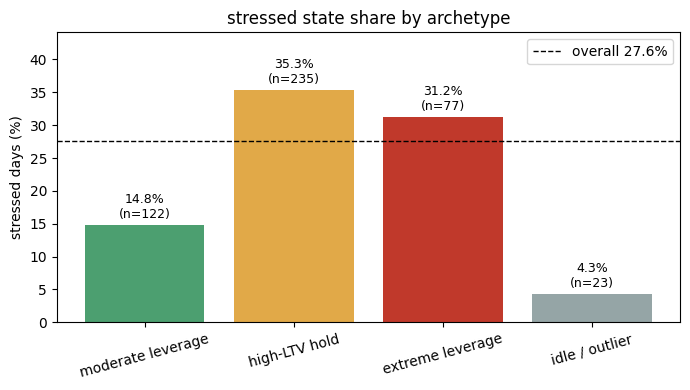

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colors = {"moderate leverage": "#4c9f70", "high-LTV hold": "#e1a948",
          "extreme leverage": "#c0392b", "idle / outlier": "#95a5a6"}
bars = ax.bar(by_arch.index, by_arch["stressed_pct"],
              color=[colors.get(a, "#888") for a in by_arch.index])
overall = panel["stressed_state"].mean() * 100
ax.axhline(overall, ls="--", c="k", lw=1, label=f"overall {overall:.1f}%")
for b, pct, n in zip(bars, by_arch["stressed_pct"], by_arch["days"]):
    ax.text(b.get_x() + b.get_width() / 2, pct + 0.6, f"{pct:.1f}%\n(n={n})",
            ha="center", va="bottom", fontsize=9)
ax.set_ylabel("stressed days (%)")
ax.set_title("stressed state share by archetype")
ax.set_ylim(0, max(by_arch["stressed_pct"]) * 1.25)
ax.legend()
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

### Why extreme leverage shows fewer stressed days than high-LTV hold

`stressed_state` is defined per whale (the lowest slice of each whale's own health factor), so the absolute rate of an archetype depends on which whales populate it, not on raw leverage alone. The two tables below show the per-whale stressed rate and the whale make-up of each archetype.

In [5]:
per_whale = (lab.groupby("whale_id")["stressed_state"].mean() * 100).round(1)
print("stressed % per whale (all labelled days):")
print(per_whale.to_string())

print("\narchetype x whale day counts:")
print(pd.crosstab(panel["cluster_name"], panel["whale_id"]).to_string())

stressed % per whale (all labelled days):
whale_id
W-1    29.5
W-2    21.3
W-3    20.1
W-4    29.6
W-5    28.6
W-6    34.1
W-7     4.4

archetype x whale day counts:
whale_id           W-1  W-2  W-3  W-4  W-5  W-6  W-7
cluster_name                                        
extreme leverage     1   75    1    0    0    0    0
high-LTV hold       76    6   67    0    0   80    6
idle / outlier       0    7   16    0    0    0    0
moderate leverage    0    0   55   26   34    7    0


Extreme leverage is 75 of 77 days a single whale, W-2, and W-2 is one of the least stress-flagged whales overall (21.3%): it sits at extreme LTV so consistently that its health factor is uniformly stretched, so its own worst slice is not much worse than its median. Extreme leverage therefore inherits that low baseline.

High-LTV hold instead pools the high-leverage days of five whales (W-1, W-3, W-6, plus a little W-2 and W-7), and high-LTV days are exactly each whale's most stressed tail. It also includes W-6, the most stress-prone whale (34.1%). Pooling several whales' worst days lifts the rate to 35.3%.

So the cross-archetype ranking is partly an artefact of the per-whale label, not evidence that extreme leverage is safer. An absolute health-factor threshold (same cut for every whale) would remove this confound and is listed under next steps.

### Absolute health-factor stress measure (adopted as primary)

The per-whale label grades each whale against its own worst days, which is a within-whale view rather than a fair comparison between archetypes. Here we judge every whale on the same absolute buffer (lower health factor, closer to liquidation, counts as stressed) and adopt this as the cross-archetype risk measure, saved as `stressed_abs` (health factor < 1.05) alongside the panel. A few buffers are shown so the result does not hinge on one magic number.

In [6]:
chk = panel.merge(lab[["whale_id", "date", "health_factor"]], on=["whale_id", "date"], how="left")
panel["health_factor"] = chk["health_factor"].to_numpy()

# absolute, cross-whale stress measure: within 5% of liquidation (health factor < 1.05)
ABS_HF = 1.05
panel["stressed_abs"] = (panel["health_factor"] < ABS_HF).astype(int)
panel.to_csv("panel_archetypes_stressed.csv", index=False)

cmp = pd.DataFrame({"per-whale label %": by_arch["stressed_pct"]})
for thr in [1.05, 1.10, 1.15]:
    rate = (
        panel.assign(s=(panel["health_factor"] < thr).astype(int))
        .groupby("cluster_name")["s"].mean() * 100
    ).round(1)
    cmp[f"HF<{thr} %"] = rate
cmp.reindex(ARCH_ORDER)

,per-whale label %,HF<1.05 %,HF<1.1 %,HF<1.15 %
cluster_name,,,,
moderate leverage,14.8,0.0,17.2,71.3
high-LTV hold,35.3,91.9,95.3,100.0
extreme leverage,31.2,100.0,100.0,100.0
idle / outlier,4.3,4.3,4.3,4.3


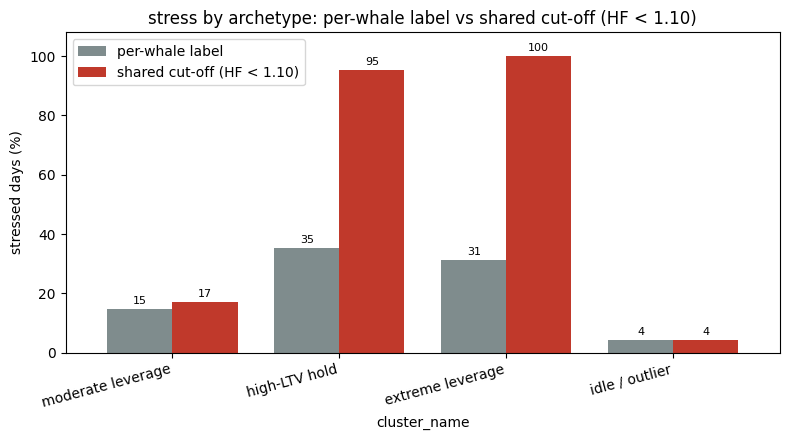

In [7]:
plot_df = cmp.reindex(ARCH_ORDER)[["per-whale label %", "HF<1.1 %"]]

ax = plot_df.plot(kind="bar", figsize=(8, 4.5), color=["#7f8c8d", "#c0392b"], width=0.78)
ax.set_ylabel("stressed days (%)")
ax.set_title("stress by archetype: per-whale label vs shared cut-off (HF < 1.10)")
ax.legend(["per-whale label", "shared cut-off (HF < 1.10)"])
ax.set_ylim(0, 108)
for c in ax.containers:
    ax.bar_label(c, fmt="%.0f", fontsize=8, padding=2)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()
plt.show()

On a single shared cut-off the ordering becomes monotonic in leverage: extreme leverage sits at or above high-LTV hold at every buffer (100% vs 92 to 100%), moderate leverage stays low, and idle stays near zero. The earlier extreme-below-high-LTV result was therefore an artefact of the per-whale label, not a sign that extreme leverage is safer. This absolute measure is saved as `stressed_abs` and used as the primary risk ranking; calibrating the exact threshold to observed liquidation events is left for later.

### Moderate leverage split by LTV (preview)

A quick look at the planned post-hoc split of moderate leverage (`LTV < 0.6` vs `>= 0.6`). This is a preview only: today it largely separates W-3's lower-LTV days from the W-4/W-5 conservative-looper core, so the full split is deferred until more whales are added.

In [8]:
mod = panel[panel["cluster_name"] == "moderate leverage"].copy()
mod["ltv_band"] = np.where(mod["ltv"] >= 0.6, "LTV >= 0.6", "LTV < 0.6")

mod_split = (
    mod.groupby("ltv_band")["stressed_state"]
    .agg(days="size", stressed_days="sum", stressed_pct="mean")
)
mod_split["stressed_pct"] = (mod_split["stressed_pct"] * 100).round(1)
print(mod_split.to_string())
print("\nwhale mix per band:")
print(mod.groupby("ltv_band")["whale_id"].value_counts().unstack(fill_value=0).to_string())

            days  stressed_days  stressed_pct
ltv_band                                     
LTV < 0.6     30              0           0.0
LTV >= 0.6    92             18          19.6

whale mix per band:
whale_id    W-3  W-4  W-5  W-6
ltv_band                      
LTV < 0.6    30    0    0    0
LTV >= 0.6   25   26   34    7


### Next steps

- Calibrate the absolute health-factor threshold to something principled (observed liquidation events or each protocol's liquidation threshold) rather than the current hand-picked 5% buffer. Needs liquidation-event data.
- Add more whales so each archetype holds several distinct wallets rather than being dominated by one. This is the deeper fix behind the per-whale artefact and the main reason the exact ranking is not yet fully trustworthy.
- Split moderate leverage (`LTV < 0.6` vs `>= 0.6`) once more whales are added, to separate W-3's light-leverage days from the W-4/W-5 conservative loopers.
- Cross stressed days with `days_since_rebalance` per archetype to test the RQ3 mechanism (stress driven by current LTV, rebalancing by accumulated LTV history).